# 05 · Survey imputation and the occupation map

Part 5 of 5. Tests how well a partial survey can be filled in, treating each O*NET occupation as a respondent.

**Reads:** O*NET raw tables, `data/derived/survey-basis-onet.parquet`, `data/raw/db_31_0_csv/job_zones.csv`
**Writes:** `data/derived/imputation-curve.png`, `occupation-map.png`

**Decisions**
- Occupations held out by 6-digit SOC so variants don't leak between train and test.
- PCA imputation (8 components) over KNN and mean-fill: KNN has the best RMSE but the worst retrieval, because it pulls profiles toward the neighborhood average.

**Results**
- Work activities, noise 0.5: PCA gets the true occupation into the top 10 for ~60% at 10 random questions, ~84% at 15.
- Knowledge + 10 skills (the locked basis), noise 0.5: ~54% at 10, ~80% at 15, ~91% at 20.
- Four PCA components explain about two-thirds of the variance: hands-on vs knowledge work, people/screens vs equipment, data vs care, creating vs servicing.
- Job Zone tracks the first component, but zones mix within knowledge work, so the app shows the education gap per suggestion.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def load_importance(name):
    df = pd.read_csv(f"../data/raw/db_31_0_csv/{name}.csv")
    df = df[(df["Scale Name"] == "Importance") & (df["Recommend Suppress"] != "Y")]
    return df.pivot(index="O*NET-SOC Code", columns="Element Name", values="Data Value")


ks = pd.read_parquet("../data/derived/survey-basis-onet.parquet").set_index("O*NET-SOC Code")
print(ks.shape)

(910, 43)


## Work activities: PCA vs KNN vs mean-fill

(911, 41)
8 components explain 80% of variance
         rmse                hit10              
method    knn   mean    pca    knn   mean    pca
n                                               
3       0.799  0.979  0.948  0.171  0.103  0.131
5       0.735  0.977  0.927  0.274  0.274  0.314
8       0.655  0.969  0.879  0.520  0.680  0.737
10      0.642  0.982  0.882  0.657  0.766  0.817
15      0.600  0.967  0.822  0.869  0.954  0.971
20      0.575  0.963  0.781  0.960  0.971  0.983
30      0.568  0.972  0.737  1.000  1.000  1.000


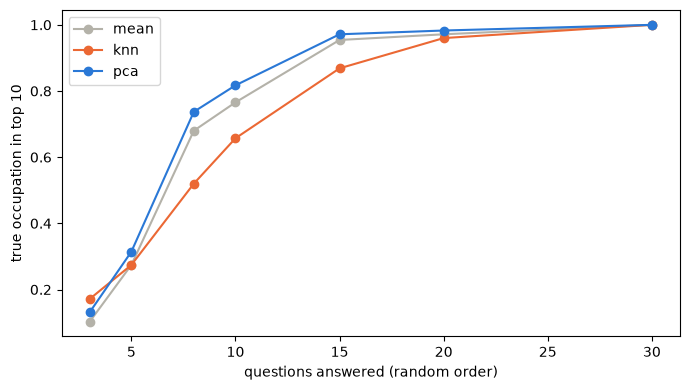

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.impute import KNNImputer
from sklearn.model_selection import GroupShuffleSplit

# 41 generalized work activities per occupation (importance, 1-5)
wa = load_importance('work_activities')
wa = wa.fillna(wa.mean())
print(wa.shape)

# hold out 20% of occupations, grouped by 6-digit SOC so variants stay together
groups = wa.index.str[:7]
tr_idx, te_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=0).split(wa, groups=groups))
mu, sd = wa.iloc[tr_idx].mean(), wa.iloc[tr_idx].std()
Z = ((wa - mu) / sd).to_numpy()
Ztr, Zte = Z[tr_idx], Z[te_idx]
d = Z.shape[1]

# PCA imputation: fit patterns on training occupations only
pca = PCA(n_components=8).fit(Ztr)
W = pca.components_
print(f'8 components explain {pca.explained_variance_ratio_.sum():.0%} of variance')

def impute_pca(x, obs, lam=1.0):
    Wo = W[:, obs]
    z = np.linalg.solve(Wo @ Wo.T + lam * np.eye(len(W)), Wo @ x[obs])
    xh = z @ W
    xh[obs] = x[obs]
    return xh

knn = KNNImputer(n_neighbors=10).fit(Ztr)

# retrieval: where does the true occupation rank among all 910?
Zn = Z / np.linalg.norm(Z, axis=1, keepdims=True)
def true_rank(xh, row):
    s = Zn @ (xh / np.linalg.norm(xh))
    return (s > s[row]).sum() + 1

rng = np.random.default_rng(0)
rows = []
for n in [3, 5, 8, 10, 15, 20, 30]:
    for row, x in zip(te_idx, Zte):
        obs = np.sort(rng.choice(d, n, replace=False))
        hid = np.setdiff1d(np.arange(d), obs)
        masked = x.copy()
        masked[hid] = np.nan
        preds = {
            'mean': np.where(np.isnan(masked), 0.0, masked),
            'knn': knn.transform(masked[None])[0],
            'pca': impute_pca(x, obs),
        }
        for name, xh in preds.items():
            rows.append({'n': n, 'method': name,
                         'rmse': np.sqrt(np.mean((xh[hid] - x[hid]) ** 2)),
                         'hit10': true_rank(xh, row) <= 10})

res = pd.DataFrame(rows).groupby(['n', 'method'])[['rmse', 'hit10']].mean().unstack()
print(res.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
for name, color in [('mean', '#b4b2a9'), ('knn', '#eb6834'), ('pca', '#2a78d6')]:
    ax.plot(res.index, res[('hit10', name)], marker='o', label=name, color=color)
ax.set_xlabel('questions answered (random order)')
ax.set_ylabel('true occupation in top 10')
ax.legend()
plt.tight_layout()
plt.savefig('../data/derived/imputation-curve.png', dpi=150)
plt.show()

## With noisy answers

In [3]:
def run(noise_sd, ns=(5, 8, 10, 15), seed=0):
    rng = np.random.default_rng(seed)
    rows = []
    for n in ns:
        for row, x in zip(te_idx, Zte):
            obs = np.sort(rng.choice(d, n, replace=False))
            hid = np.setdiff1d(np.arange(d), obs)
            xn = x.copy()
            xn[obs] += rng.normal(0, noise_sd, n)
            masked = xn.copy()
            masked[hid] = np.nan
            preds = {
                'mean': np.where(np.isnan(masked), 0.0, masked),
                'knn': knn.transform(masked[None])[0],
                'pca': impute_pca(xn, obs),
            }
            for name, xh in preds.items():
                rows.append({'n': n, 'method': name, 'hit10': true_rank(xh, row) <= 10})
    return pd.DataFrame(rows).groupby(['n', 'method'])['hit10'].mean().unstack()

for noise in [0.0, 0.5, 1.0]:
    print(f'noise sd = {noise}')
    print(run(noise).round(3), '\n')

noise sd = 0.0
method    knn   mean    pca
n                          
5       0.251  0.371  0.337
8       0.566  0.657  0.657
10      0.589  0.691  0.720
15      0.846  0.891  0.943 

noise sd = 0.5
method    knn   mean    pca
n                          
5       0.211  0.234  0.257
8       0.480  0.509  0.520
10      0.423  0.526  0.549
15      0.743  0.800  0.800 

noise sd = 1.0
method    knn   mean    pca
n                          
5       0.120  0.126  0.120
8       0.263  0.240  0.297
10      0.229  0.257  0.280
15      0.497  0.509  0.549 



### Five seeds, plus top-1 similarity

In [4]:
def run(noise_sd, ns=(5, 8, 10, 15), seed=0):
    rng = np.random.default_rng(seed)
    rows = []
    for n in ns:
        for row, x in zip(te_idx, Zte):
            obs = np.sort(rng.choice(d, n, replace=False))
            hid = np.setdiff1d(np.arange(d), obs)
            xn = x.copy()
            xn[obs] += rng.normal(0, noise_sd, n)
            masked = xn.copy()
            masked[hid] = np.nan
            preds = {
                'mean': np.where(np.isnan(masked), 0.0, masked),
                'knn': knn.transform(masked[None])[0],
                'pca': impute_pca(xn, obs),
            }
            for name, xh in preds.items():
                s = Zn @ (xh / np.linalg.norm(xh))
                top = s.argmax()
                rows.append({'n': n, 'method': name,
                             'hit10': (s > s[row]).sum() + 1 <= 10,
                             'top1_sim': Zn[top] @ Zn[row]})
    return pd.DataFrame(rows)

for noise in [0.0, 0.5, 1.0]:
    df = pd.concat([run(noise, seed=s) for s in range(5)])
    print(f'noise sd = {noise}  (5 seeds)')
    print(df.groupby(['n', 'method'])[['hit10', 'top1_sim']].mean().unstack().round(3), '\n')

noise sd = 0.0  (5 seeds)
        hit10               top1_sim              
method    knn   mean    pca      knn   mean    pca
n                                                 
5       0.297  0.345  0.344    0.619  0.492  0.547
8       0.510  0.585  0.638    0.700  0.643  0.684
10      0.593  0.729  0.766    0.743  0.723  0.757
15      0.856  0.926  0.959    0.852  0.868  0.905 

noise sd = 0.5  (5 seeds)
        hit10               top1_sim              
method    knn   mean    pca      knn   mean    pca
n                                                 
5       0.203  0.234  0.246    0.546  0.438  0.477
8       0.390  0.455  0.479    0.636  0.560  0.610
10      0.467  0.576  0.597    0.673  0.619  0.663
15      0.733  0.822  0.842    0.777  0.783  0.819 

noise sd = 1.0  (5 seeds)
        hit10               top1_sim              
method    knn   mean    pca      knn   mean    pca
n                                                 
5       0.112  0.122  0.135    0.427  0.342  0.374


## What the components mean

In [5]:
for i in range(4):
    load = pd.Series(pca.components_[i], index=wa.columns).sort_values()
    print(f'component {i+1}  ({pca.explained_variance_ratio_[i]:.0%} of variance)')
    print('  low end: ', ', '.join(load.index[:3]))
    print('  high end:', ', '.join(load.index[-3:]), '\n')

component 1  (37% of variance)
  low end:  Handling and Moving Objects, Controlling Machines and Processes, Performing General Physical Activities
  high end: Organizing, Planning, and Prioritizing Work, Developing Objectives and Strategies, Providing Consultation and Advice to Others 

component 2  (17% of variance)
  low end:  Working with Computers, Establishing and Maintaining Interpersonal Relationships, Communicating with People Outside the Organization
  high end: Controlling Machines and Processes, Repairing and Maintaining Mechanical Equipment, Inspecting Equipment, Structures, or Materials 

component 3  (9% of variance)
  low end:  Processing Information, Analyzing Data or Information, Working with Computers
  high end: Assisting and Caring for Others, Resolving Conflicts and Negotiating with Others, Performing for or Working Directly with the Public 

component 4  (5% of variance)
  low end:  Thinking Creatively, Drafting, Laying Out, and Specifying Technical Devices, Parts

## Reference: how similar are occupations to their own neighbors?

In [6]:
S_wa = Zn @ Zn.T
np.fill_diagonal(S_wa, -np.inf)
sorted_sims = -np.sort(-S_wa, axis=1)

ref = pd.Series({
    '1st nearest neighbor': np.median(sorted_sims[:, 0]),
    '5th nearest neighbor': np.median(sorted_sims[:, 4]),
    '10th nearest neighbor': np.median(sorted_sims[:, 9]),
    '50th nearest neighbor': np.median(sorted_sims[:, 49]),
})
print(ref.round(3))

1st nearest neighbor     0.827
5th nearest neighbor     0.765
10th nearest neighbor    0.729
50th nearest neighbor    0.600
dtype: float64


## Occupation map

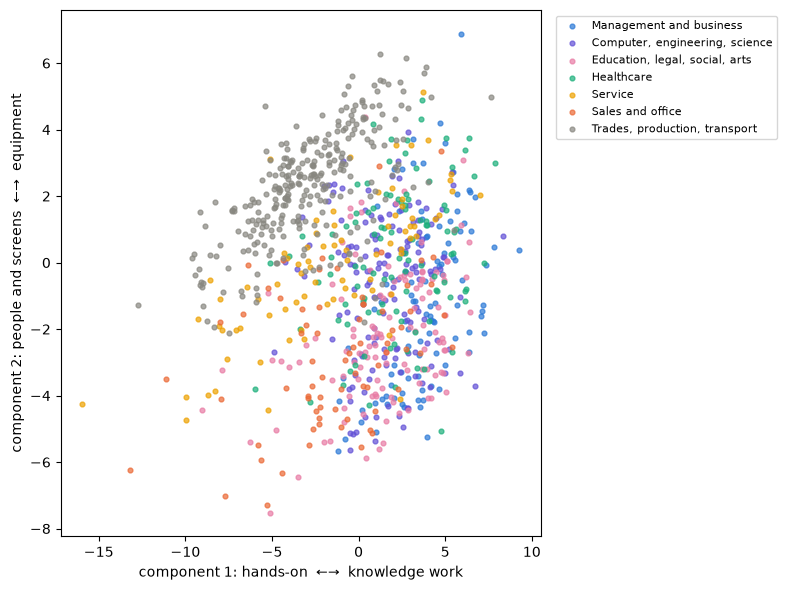

In [7]:
families = {
    'Management and business': ['11', '13'],
    'Computer, engineering, science': ['15', '17', '19'],
    'Education, legal, social, arts': ['21', '23', '25', '27'],
    'Healthcare': ['29', '31'],
    'Service': ['33', '35', '37', '39'],
    'Sales and office': ['41', '43'],
    'Trades, production, transport': ['45', '47', '49', '51', '53'],
}
colors = ['#2a78d6', '#6250d6', '#e87ba4', '#1baf7a', '#eda100', '#eb6834', '#888780']
fam_of = {g: f for f, gs in families.items() for g in gs}

coords = pca.transform(Z)[:, :2]
fam = pd.Series(wa.index.str[:2]).map(fam_of).to_numpy()

fig, ax = plt.subplots(figsize=(8, 6))
for (f, _), c in zip(families.items(), colors):
    m_ = fam == f
    ax.scatter(coords[m_, 0], coords[m_, 1], s=12, alpha=0.7, color=c, label=f)
ax.set_xlabel('component 1: hands-on  ←→  knowledge work')
ax.set_ylabel('component 2: people and screens  ←→  equipment')
ax.legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig('../data/derived/occupation-map.png', dpi=150)
plt.show()

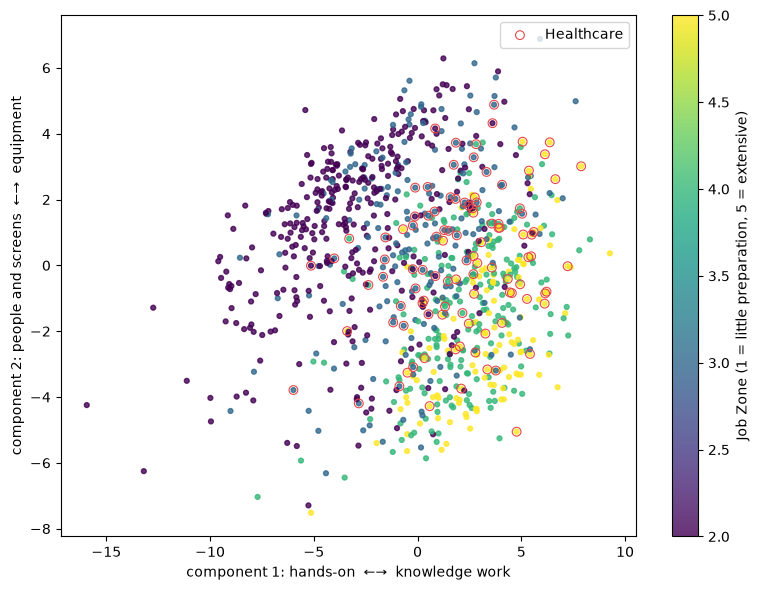

In [8]:
jz_raw = pd.read_csv('../data/raw/db_31_0_csv/job_zones.csv')
zone_wa = jz_raw.set_index('O*NET-SOC Code')['Job Zone'].reindex(wa.index).to_numpy()

fig, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter(coords[:, 0], coords[:, 1], c=zone_wa, cmap='viridis', s=12, alpha=0.8)
hc = fam == 'Healthcare'
ax.scatter(coords[hc, 0], coords[hc, 1], facecolors='none', edgecolors='#e34948', s=40, linewidths=0.8, label='Healthcare')
ax.set_xlabel('component 1: hands-on  ←→  knowledge work')
ax.set_ylabel('component 2: people and screens  ←→  equipment')
plt.colorbar(sc, label='Job Zone (1 = little preparation, 5 = extensive)')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

## Locked basis (knowledge + 10 skills) under the same test

In [9]:
groups_ks = ks.index.str[:7]
tr_i, te_i = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=0).split(ks, groups=groups_ks))
mu_k, sd_k = ks.iloc[tr_i].mean(), ks.iloc[tr_i].std()
Zk = ((ks - mu_k) / sd_k).to_numpy()
Zk_te = Zk[te_i]
dk = Zk.shape[1]
Zk_n = Zk / np.linalg.norm(Zk, axis=1, keepdims=True)

pca_k = PCA(n_components=8).fit(Zk[tr_i])
Wk = pca_k.components_
print(f'8 components explain {pca_k.explained_variance_ratio_.sum():.0%} of variance')

def impute_k(x, obs, lam=1.0):
    Wo = Wk[:, obs]
    z = np.linalg.solve(Wo @ Wo.T + lam * np.eye(len(Wk)), Wo @ x[obs])
    xh = z @ Wk
    xh[obs] = x[obs]
    return xh

def run_k(noise_sd, ns=(5, 8, 10, 15, 20), seed=0):
    rng = np.random.default_rng(seed)
    rows = []
    for n in ns:
        for row, x in zip(te_i, Zk_te):
            obs = np.sort(rng.choice(dk, n, replace=False))
            xn = x.copy()
            xn[obs] += rng.normal(0, noise_sd, n)
            masked = np.where(np.isin(np.arange(dk), obs), xn, 0.0)
            for name, xh in {'mean': masked, 'pca': impute_k(xn, obs)}.items():
                s = Zk_n @ (xh / np.linalg.norm(xh))
                rows.append({'n': n, 'method': name,
                             'hit10': (s > s[row]).sum() + 1 <= 10,
                             'top1_sim': Zk_n[s.argmax()] @ Zk_n[row]})
    return pd.DataFrame(rows)

res_k = pd.concat([run_k(0.5, seed=s) for s in range(3)])
print(res_k.groupby(['n', 'method'])[['hit10', 'top1_sim']].mean().unstack().round(3))

8 components explain 77% of variance
        hit10        top1_sim       
method   mean    pca     mean    pca
n                                   
5       0.167  0.184    0.410  0.451
8       0.442  0.484    0.524  0.574
10      0.494  0.537    0.587  0.640
15      0.750  0.798    0.718  0.758
20      0.882  0.909    0.827  0.868


In [25]:
# reuse from notebook 05: ks, Zk (standardized), tr_i, te_i, Zk_te, dk, Zk_n, impute_k, Wk
items = ks.columns


def score_set(idx, noise_sd=0.5, seeds=range(3)):
    """hit@10 on held-out occupations when only the items in idx are answered."""
    # TODO: like run_k, but obs = idx (fixed) instead of a random choice
    rows = []
    for seed in seeds:
        rng = np.random.default_rng(seed)
        for row, x in zip(te_i, Zk_te):
            obs = idx
            xn = x.copy()
            xn[obs] += rng.normal(0, noise_sd, len(idx))

            for name, xh in {"pca": impute_k(xn, obs)}.items():
                s = Zk_n @ (xh / np.linalg.norm(xh))
                rows.append(
                    {
                        "len": len(idx),
                        "method": name,
                        "hit10": (s > s[row]).sum() + 1 <= 10,
                    }
                )
    df = pd.DataFrame(rows)
    return df["hit10"].mean()


# method 1: spread on the raw 1-5 scale, training occupations only
# TODO: per-item std of ks.iloc[tr_i]; take the top 15
m1 = ...

# method 2: PCA loadings
# TODO: for each of the first k components, take the items with the largest |loading| in Wk
m2 = ...

# method 3: greedy, least correlated with what's already picked
# TODO: start from the top-spread item; repeatedly add the candidate whose max |corr| with the chosen set is smallest
m3 = ...

# method 4 (optional): greedy on score_set itself
# TODO: start empty; at each step add the item that most increases score_set(chosen + [item])
#       note: score on a validation split of the training occupations, not te_i
m4 = ...

print(score_set(rng.choice(dk, 15, replace=False)))
rng = np.random.default_rng(1)
scores = []
for _ in range(10):
    answered = rng.choice(dk, 15, replace=False)
    scores.append(score_set(answered))
print(pd.Series(scores).describe().round(3))
results = {
    name: score_set(s)
    for name, s in [
        ("spread", m1),
        ("pca", m2),
        ("greedy corr", m3),
        ("greedy metric", m4),
    ]
}
print(pd.Series(results).round(3))
print("random 15 baseline: ~0.80")
for name, s in [("spread", m1), ("pca", m2), ("greedy corr", m3)]:
    print(name, list(items[s]))

0.7674418604651163
count    10.000
mean      0.791
std       0.054
min       0.694
25%       0.757
50%       0.798
75%       0.816
max       0.866
dtype: float64


TypeError: object of type 'ellipsis' has no len()